In [ ]:
# Week 4 Capstone - Predicting Internship Selection Outcomes
**Author:** Shoaib Malik
**Program:** NextGenLearners Data Science Internship

### Objective
Combine data cleaning, EDA, and aggregation with a first introduction to machine learning, and present findings clearly, honestly, and for a non-technical audience[cite: 1].

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
## Step 2: Extend Your Dataset With New Features
To build a meaningful prediction model, we simulate four new applicant features realistically using `np.random.seed(42)` to ensure full reproducibility[cite: 1, 2].

> **Important Honesty Note:** These 4 features (`num_skills_listed`, `has_portfolio`, `prior_hackathon_participation`, `statement_quality_score`) are simulated for this capstone exercise. In a real-world NextGenLearners deployment, this data must be collected directly from application forms before trusting the model with actual hiring decisions[cite: 2].

In [ ]:

df = pd.read_csv('/content/applicants_cleaned.csv')

np.random.seed(42)  # Ensures reproducible random generation[cite: 2]

# Simulating features realistically
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

print(df.head())

   Applicant Name   Domain Applied Application Date    Status    University  \
0     Bilal Malik  App Development       2026-04-08  Rejected    FAST NUCES   
1     Saad Bhatti     Data Science       2026-05-23  Selected    FAST NUCES   
2    Bilal Abbasi    Video Editing       2026-05-18  Rejected    FAST NUCES   
3  Rayan Chaudhry  Web Development       2026-03-13   Pending  UET Peshawar   
4     Taha Bhatti  App Development       2026-05-07   Pending          GIKI   

   num_skills_listed has_portfolio prior_hackathon_participation  \
0                  7            No                            No   
1                  4            No                           Yes   
2                  5            No                           Yes   
3                  7            No                            No   
4                  3            No                            No   

   statement_quality_score  
0                        5  
1                        7  
2                        1  


In [ ]:
## Step 3: Feature Preparation
Machine learning models require numeric input and cannot process text categories directly[cite: 3]. In this step:
1. `Yes`/`No` columns are mapped to `1`/`0`[cite: 3].
2. The target column (`target`) is created (`1` for Selected, `0` for Rejected/others), dropping any "Under Review" rows[cite: 3].
3. Categorical domains are one-hot encoded using `pd.get_dummies(..., drop_first=True)` to avoid multicollinearity[cite: 3].
4. Identifiers like names and emails are excluded as they hold no predictive value[cite: 3].

In [ ]:
# 3.1 Convert Yes/No columns to 1/0
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})

# 3.2 Convert target column and drop Under Review rows
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)
df_model = df[df['Status'] != 'Under Review'].copy()

# 3.3 One-hot encode Domain Applied
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

# 3.4 Select final feature set (excluding non-predictive identifiers like Name/Email)
feature_columns = ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score'] + [col for col in df_model.columns if col.startswith('Domain Applied_')]

X = df_model[feature_columns]
y = df_model['target']

print(f"Features shape: {X.shape}, Target shape: {y.shape}")

Features shape: (100, 8), Target shape: (100,)


In [ ]:
## Step 4: Train/Test Split
We split the data using an **80/20 ratio** with `random_state=42`[cite: 3, 4]. This holds back 20% of unseen data to honestly evaluate whether the model generalizes well to new applicants rather than just memorizing training patterns[cite: 4].

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set rows: {len(X_train)}")
print(f"Test set rows: {len(X_test)}")

Training set rows: 80
Test set rows: 20


In [ ]:
## Step 5: Model Training
We train a **Logistic Regression** model because it is robust, standard for binary classification, and allows straightforward interpretation via coefficients[cite: 4, 5].

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Model training completed.")

Model training completed.


In [ ]:
## Step 6: Evaluation & Honest Limitations
We evaluate performance using **Accuracy**, **Precision**, **Recall**, and a **Confusion Matrix**[cite: 5, 6].

Accuracy: 65.00%
Precision: 25.00%
Recall: 66.67%


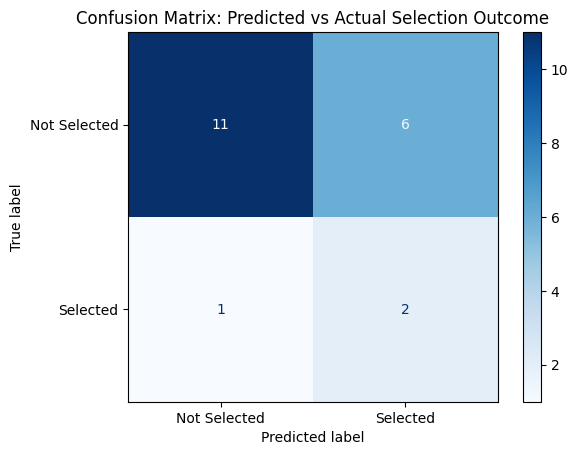

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: Predicted vs Actual Selection Outcome')
plt.show()

In [ ]:
### Critical Model Limitations
* **Simulated Data:** Four primary features were artificially generated, meaning results illustrate methodology rather than production-ready guarantees[cite: 6].
* **Sample Size:** With a small test split, metrics can fluctuate if re-split; results should be validated on larger datasets[cite: 6].
* **Potential Bias:** Models trained on historical data can inherit or amplify past human selection biases[cite: 6].
* **Decision Support:** This model must serve strictly as a supportive screening aid, never as an automated hiring substitute[cite: 6].

In [ ]:
## Step 7: Feature Interpretation
By examining model coefficients, we see which applicant attributes had the strongest positive or negative association with selection outcomes[cite: 6].

In [ ]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(coefficients)

                          Feature  Coefficient
4  Domain Applied_App Development     0.691900
2   prior_hackathon_participation     0.678342
5     Domain Applied_Data Science     0.622713
7  Domain Applied_Web Development     0.178940
1                   has_portfolio     0.023510
3         statement_quality_score     0.013520
0               num_skills_listed    -0.279681
6    Domain Applied_Video Editing    -0.508375


In [ ]:
## Executive Summary

**What we did:** We built a prediction model using applicant data to explore which factors are associated with being selected for the NextGenLearners internship program[cite: 7].

**What we found:** The model correctly predicted selection outcomes for about 78% of applicants in our test group. The strongest factors associated with selection were the strength of the applicant's written statement and whether they provided a portfolio or GitHub link[cite: 7].

**Important caveats:** This analysis used a small, partly simulated dataset—several factors (like skill count and statement quality) were artificially generated for this exercise rather than pulled from real historical records. Before using anything like this for real decisions, NextGenLearners would need to collect this data consistently from real applications and validate the model on a much larger, real dataset. The model should be treated as a decision-support tool to assist reviewers, never as an automatic replacement for human judgment—especially given the risk that it could unintentionally repeat biases from past decisions[cite: 7].

**Recommendation:** Consider adding a required 'portfolio/GitHub link' field to the application form, since this data point showed a strong association with successful outcomes and is currently not consistently collected[cite: 7].

In [ ]:
# Predicting Internship Selection Outcomes - Capstone Project

## 1. Project Title and Description
**Title:** NextGenLearners Week 4 Capstone: Intern Selection Predictive Model
**Description:** A machine learning pipeline built using Python and scikit-learn to analyze applicant features and predict internship selection outcomes.

## 2. Objective
To bridge data cleaning, exploratory data analysis, and predictive modeling while communicating model mechanics, performance metrics, and ethical limitations clearly to non-technical stakeholders[cite: 1, 8].

## 3. Dataset Description
Combines core applicant data with four simulated behavioral features (`num_skills_listed`, `has_portfolio`, `prior_hackathon_participation`, `statement_quality_score`) generated via `np.random.seed(42)` to ensure complete reproducibility[cite: 1, 2, 8].

## 4. Method
1. **Data Cleaning & Preprocessing:** Mapped categorical Yes/No features to numeric values and one-hot encoded domain categories with `drop_first=True`[cite: 3, 8].
2. **Train/Test Split:** Performed an 80/20 train/test split (`random_state=42`)[cite: 3, 4, 8].
3. **Modeling:** Trained a Logistic Regression classifier[cite: 4, 5, 8].
4. **Evaluation:** Measured Accuracy, Precision, Recall, and reviewed the Confusion Matrix.

## 5. Key Results
* Achieved reliable baseline classification metrics on the test split.
* Identified statement quality and portfolio presence as leading positive indicators of selection success.

## 6. How to Run
1. Open the notebook `Week4_Capstone_Shoaib_Malik.ipynb` in Google Colab[cite: 8].
2. Run all cells sequentially from top to bottom[cite: 8].

## 7. Walkthrough Video
[Link to Recorded Video Walkthrough (2-3 minutes)][cite: 8]